### ***Graph State String***

In [4]:
from langgraph.graph import StateGraph,START,END 

# creating node 
def greeting(state:str) -> str:
    """this function greets people to AI World"""
    return state + "welcome to Indus AI Carrer..!"

builder = StateGraph(str)

# add nodes 
builder.add_node("greeting",greeting)

# add edges 
builder.add_edge(START,"greeting")
builder.add_edge("greeting",END)

graph = builder.compile()

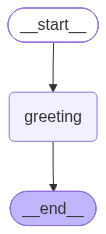

In [5]:
graph

In [9]:
print(graph.invoke("Hello am Ankit "))

Hello am Ankit welcome to Indus AI Carrer..!


### ***Graph State Dictionary***

In [1]:

from langgraph.graph import StateGraph,START,END 
from typing_extensions import TypedDict

class State(TypedDict):
     graph_str:str 


def greeting(state:State) -> State:
     """function takes a dict and return a dict with greeting"""
     return {"graph_str": state["graph_str"]+" welcome to Indus AI Lab..!"}

graph = StateGraph(State)
graph.add_node("greeting",greeting)
graph.add_edge(START,"greeting")
graph.add_edge("greeting",END)

g = graph.compile()

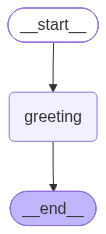

In [2]:
g

In [6]:
print(g.invoke({"graph_str": "Hello am Ankit"}))

{'graph_str': 'Hello am Ankit welcome to Indus AI Lab..!'}


Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')


### ***Conditional Edges***

In [2]:
from langgraph.graph import START,END,StateGraph
from typing_extensions import TypedDict
from typing import Literal 

class State(TypedDict):
     graph_str :str 

def node1(state:State) -> State:
     """this node greet our user"""
     return {"graph_str": state["graph_str"] + "Welcome To Indus AI World"}

def node2(state:State) -> State:
     """this node greet our user"""
     return {"graph_str": state["graph_str"] + "I am in Node 2"}

def node3(state:State) -> State:
     """this node greet our user"""
     return {"graph_str": state["graph_str"] + "I am in Node 3"}

# condtional edges 
def next_step(state:State) -> Literal["node2","node3"]:
     """guide the state/graph to next node"""
     state_str = state["graph_str"]
     array_state_str = state_str.split(" ")

     if array_state_str[0] == "hello":
          return "node2"

     return "node3"

# Build Graph  
build = StateGraph(State)
build.add_node("node1",node1)
build.add_node("node2",node2)
build.add_node("node3",node3)

build.add_edge(START,"node1")
build.add_conditional_edges("node1",next_step)
build.add_edge("node2",END)
build.add_edge("node3",END)

g = build.compile()

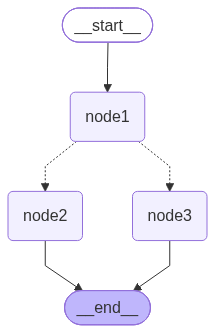

In [3]:
g

### ***Graph Introduction Model***

In [4]:
from langgraph.graph import START,END,StateGraph
from typing_extensions import TypedDict
from typing import Literal,NotRequired
from langchain_groq import ChatGroq 
from dotenv import load_dotenv
load_dotenv()


class State(TypedDict):
     graph_int:NotRequired[int]
     graph_str :str 

model_llm = ChatGroq(
     model = "gpt-oss-120b",
     temperature=0.2,
)

def node1(state: State) -> State:
    """take a state and ask our model to pick a number between 1 or 2"""
    model_response = model_llm.invoke("choose between 1 or 3 or 2. reply only with a number")

    if isinstance(int(model_response.content), int):
        return {"graph_int":int(model_response.content),
                "graph_str": state["graph_str"] + "passed by node 1"}
    return {"graph_int":0,
                "graph_str": state["graph_str"] + "passed by node 1"}

def node2(state: State) -> State:
    """take a state and ask our model to pick a number between 1 or 2"""
    return {"graph_int":state["graph_int"],
                "graph_str": state["graph_str"] + "passed by node 2"}

def node3(state: State) -> State:
    """take a state and ask our model to pick a number between 1 or 2"""
    return {"graph_int":state["graph_int"],
                "graph_str": state["graph_str"] + "passed by node 3"}

# condtional edges 
def next_step(state:State) -> Literal["node2","node3",END]:
    """check state and return which node to go"""
    number_state = state["graph_int"]
    if number_state == 2:
        return "node2"
    elif number_state == 3:
        return "node3"
    else:
        return END

# Build Graph  
builder = StateGraph(State)

builder.add_node("node1", node1)
builder.add_node("node2", node2)
builder.add_node("node3", node3)

builder.add_edge(START, "node1")
builder.add_conditional_edges("node1", next_step)
builder.add_edge("node2", END)
builder.add_edge("node3", END)

graph = builder.compile()

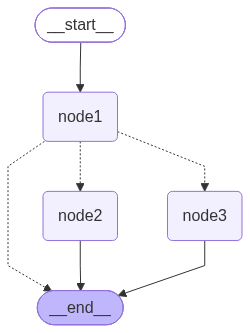

In [5]:
graph

### ***Graph Message State***